# Zaključna primerjava — Regresija: Olist
**Isti podatki in semena · vaše izbrane nastavitve · validacija in test**

Ta notebook izvedemo **na koncu regresijskega sklopa**, ko so hiperparametri že izbrani na validaciji.
Vnesite svojo oznako in nastavitve iz razvojnih vaj, nato izvedite celice po vrsti.
Privzete nastavitve so delujoč primer predavatelja, ne obvezna izbira udeležencev.

1. Nastavitve in nabor značilk določimo pred odpiranjem testa.
2. Vse modele naučimo na isti učni množici. Za GBT izberemo število dreves z validacijo.
3. Na validaciji izberemo kandidata za skupno primerjavo.
4. Iste naučene modele ocenimo na testu in primerjamo oba rezultata.
5. Izvozimo CSV in JSON ter primerjamo oddaje udeležencev.

**Skupno seme je 42.** Delitev in vrstni red vrstic ostaneta shranjena; podatkov ne delimo na novo.
Število niti je 2. Linearni postopki brez naključnosti semena ne potrebujejo.
Različice knjižnic shranimo z rezultati; enako seme ne zagotavlja bitno enakih rezultatov na vseh računalnikih in različicah.

Glavna metrika je **MAE v dnevih**, manj je bolje. Dogovor ostane enak za vse udeležence.
Po ogledu testa nastavitev ne prilagajamo njegovemu rezultatu; nadaljnji poskusi bi bili raziskovalni, ne nov neodvisen test.
V notebooku se modeli **ne učijo na train + val**, zato sta prikazani validacijska in testna ocena istega modela neposredno primerljivi.

Skupna funkcija samodejno pripravi delitve iz poglavja `02_preverjanje_modela`. Potrebujete okolje iz `requirements.txt`.
Predviden čas je približno 15–20 minut za izvedbo in skupno razpravo.

Podatke po potrebi pripravi `poskrbi_za_modeliranje`; `preberi_tabelo` jih bere s tipi iz sheme.

In [ ]:
#@title Nastavitev okolja (kliknite za prikaz kode)
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/valira-ai/ui-za-poslovne-aplikacije.git"

if "google.colab" in sys.modules:
    KOREN = Path("/content/ui-za-poslovne-aplikacije")
    if not (KOREN / "utils/orodja.py").is_file():
        if KOREN.exists():
            raise FileNotFoundError(f"Mapa {KOREN} že obstaja, vendar v njej ni utils/orodja.py.")
        subprocess.run(["git", "clone", "-q", REPO_URL, str(KOREN)], check=True)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", str(KOREN / "requirements.txt")],
        check=True,
    )
else:
    KOREN = Path.cwd().resolve()
    while not (KOREN / "utils/orodja.py").is_file() and KOREN != KOREN.parent:
        KOREN = KOREN.parent
    if not (KOREN / "utils/orodja.py").is_file():
        raise FileNotFoundError("Zaženite zvezek v prenesenem repozitoriju ali njegovi podmapi (manjka utils/orodja.py).")

if str(KOREN) not in sys.path:
    sys.path.insert(0, str(KOREN))
print("Gradivo je v:", KOREN)


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
import copy
import hashlib
import json
import re
import uuid
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sklearn
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    log_loss, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
    mean_absolute_error, mean_squared_error, r2_score,
)

SEME=42  # Skupni dogovor delavnice: ne spreminjajte.
N_JOBS=2
if SEME!=42 or N_JOBS!=2:
    raise ValueError('Za skupno primerjavo uporabite SEME=42 in N_JOBS=2.')
np.random.seed(SEME)
pd.set_option('display.max_columns',14)
pd.set_option('display.max_rows',20)
plt.rcParams.update({'figure.figsize':(10,5),'font.size':11})
RAZLICICE={'python':platform.python_version(),'numpy':np.__version__,
           'pandas':pd.__version__,'sklearn':sklearn.__version__,'lightgbm':lgb.__version__}
print('Različice:',RAZLICICE)

def json_besedilo(x):
    return json.dumps(x,ensure_ascii=False,sort_keys=True,allow_nan=False)

def odtis(x):
    return hashlib.sha256(json_besedilo(x).encode()).hexdigest()

def datotecni_odtis(p):
    with Path(p).open('rb') as f:
        return hashlib.file_digest(f,'sha256').hexdigest() if hasattr(hashlib,'file_digest') else hashlib.sha256(f.read()).hexdigest()

ZBIRKA='olist'
GLAVNA_METRIKA='MAE'

## 1. Najprej učni in validacijski podatki
Beremo iste dopolnjene tabele kot v razvojnih notebookih. Učne mediane so bile določene pred tem.
Kodiranje in morebitno skaliranje se ponovno naučita samo na učnih podatkih.

In [ ]:
from utils.modeliranje import poskrbi_za_modeliranje, preberi_shemo, preberi_tabelo
PODATKI = poskrbi_za_modeliranje(ZBIRKA)
shema = preberi_shemo(PODATKI / "shema.json")
CILJ, KLJUC = shema["cilj"], shema["kljuc"]
DATUMI = shema["datumski_stolpci"]

# Testa tukaj še ne beremo.
train = preberi_tabelo(PODATKI / "train.csv", shema)
val = preberi_tabelo(PODATKI / "val.csv", shema)
assert train[KLJUC].is_unique and val[KLJUC].is_unique
assert set(train[KLJUC]).isdisjoint(val[KLJUC])
VSE=shema['znacilke']
assert not set(shema['metapodatki']+[CILJ]) & set(VSE)

In [3]:
KATEGORIJE=shema['kategoricne_znacilke']
PRIVZETE=list(shema['nabori_znacilk']['kosarica_in_lokacija'])
meja_val=pd.Timestamp(shema['delitev']['zacetek_val'])
meja_test=pd.Timestamp(shema['delitev']['zacetek_test'])
assert (train.datum_nakupa<meja_val).all() and (train.datum_znanega_izida<meja_val).all()
assert (val.datum_nakupa>=meja_val).all() and (val.datum_nakupa<meja_test).all()
assert (val.datum_znanega_izida<meja_test).all()
for df in [train,val]:
    np.testing.assert_allclose(df[CILJ],(df.datum_znanega_izida-df.datum_nakupa).dt.total_seconds()/86400,atol=1e-9)

Pri Olistu test predstavlja poznejša naročila. Razlika med validacijo in testom lahko zato odraža tudi spremembo skozi čas.
Vzorec vsebuje naročila z znano dostavo; filtriranje po času znanega izida ob mejah lahko izloči dolge dostave blizu meje.
Datum dejanske dostave in ID-ji niso vhodne značilke.

## 2. Vnesite svoje izbrane nastavitve
Spremenite oznako udeleženca ter hiperparametre modelov. Nabor značilk je skupen vsem modelom te oddaje;
lahko uporabite tudi svoj prej preverjeni nabor iz dovoljenih stolpcev sheme.
Semena in število niti ostanejo skupna. Primerjava udeležencev upošteva isti cilj, podatke, delitev in glavno metriko.
Vsaka oddaja vsebuje vse modele in zapis njihovih dejanskih nastavitev.

In [4]:
UDELEZENEC='primer_predavatelja'  # Zamenjajte s svojo oznako.
ZNACILKE=list(PRIVZETE)
LINEARNA=dict(fit_intercept=True)
POLINOMSKA=dict(fit_intercept=True)
STOPNJA_POLINOMA=2
DREVO=dict(max_depth=6,min_samples_leaf=30)
GOZD=dict(n_estimators=80,max_depth=12,min_samples_leaf=30,max_features=.8)
GBT=dict(n_estimators=800,learning_rate=.05,num_leaves=15,max_depth=5,
         min_child_samples=100,reg_lambda=1.0)
POTRPEZLJIVOST=40
NASTAVITVE=dict(linearna=LINEARNA,polinomska=POLINOMSKA,stopnja=STOPNJA_POLINOMA,
                drevo=DREVO,gozd=GOZD,gbt=GBT,potrpezljivost=POTRPEZLJIVOST)

In [5]:
if not isinstance(UDELEZENEC,str) or not UDELEZENEC.strip():
    raise ValueError('Vnesite svojo oznako udeleženca.')
if not ZNACILKE or len(set(ZNACILKE))!=len(ZNACILKE) or not set(ZNACILKE)<=set(VSE):
    raise ValueError('Izberite veljaven, enoličen nabor vhodnih značilk.')
KAT=[s for s in KATEGORIJE if s in ZNACILKE]
NUM=[s for s in ZNACILKE if s not in KATEGORIJE and not s.endswith('_manjka')]
IND=[s for s in ZNACILKE if s not in KAT+NUM]

def vhod(df):
    X=df[ZNACILKE].copy()
    assert not X.isna().any().any(), 'Uporabite dopolnjene tabele.'
    X[KAT]=X[KAT].astype(str)
    assert np.isfinite(X[NUM+IND].to_numpy(float)).all()
    return X

X_train,X_val=vhod(train),vhod(val)
y_train,y_val=train[CILJ],val[CILJ]

def priprava(standardiziraj=False,stopnja=None):
    if stopnja is not None:
        st_numericnih=len(NUM)
        if stopnja not in [1,2,3]:
            raise ValueError('Za to vajo izberite stopnjo polinoma 1, 2 ali 3.')
        from math import comb
        if comb(st_numericnih+stopnja,stopnja)-1>1200:
            raise ValueError('Polinom bi bil prevelik. Zmanjšajte stopnjo ali nabor značilk za celotno primerjavo.')
        numericni=Pipeline([('scale',StandardScaler()),('poly',PolynomialFeatures(stopnja,include_bias=False)),
                            ('scale_poly',StandardScaler())])
    else:
        numericni=StandardScaler() if standardiziraj else 'passthrough'
    return ColumnTransformer([
        ('num',numericni,NUM),('ind','passthrough',IND),
        ('kat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),KAT),
    ],remainder='drop')

# Število niti in semena so skupna, ne del posameznikovega iskanja.
def s_skupnimi(uporabniske,fiksne):
    for k,v in fiksne.items():
        if k in uporabniske and uporabniske[k]!=v:
            raise ValueError(f'{k} mora biti za skupno primerjavo {v!r}.')
    # Alternativna imena ne smejo obiti dogovorjenih nastavitev.
    for k in ['num_threads','num_thread','nthread','random_seed','bagging_fraction_seed']:
        if k in uporabniske:
            raise ValueError(f'Ne uporabljajte vzdevka {k}; skupna semena in niti so že določeni.')
    return {**uporabniske,**fiksne}

SKUPNI_GBT=dict(random_state=SEME,seed=SEME,bagging_seed=SEME,
    feature_fraction_seed=SEME,data_random_seed=SEME,extra_seed=SEME,drop_seed=SEME,
    n_jobs=N_JOBS,deterministic=True,force_col_wise=True,boosting_type='gbdt',
    boost_from_average=True,verbosity=-1)
if GBT.get('subsample',1)<1 and GBT.get('subsample_freq',0)==0:
    raise ValueError('Pri subsample < 1 nastavite tudi subsample_freq > 0.')

ZAMRZNJENO=copy.deepcopy(dict(udelezenec=UDELEZENEC.strip(),seme=SEME,n_jobs=N_JOBS,
    znacilke=ZNACILKE,nastavitve=NASTAVITVE,glavna_metrika=GLAVNA_METRIKA))
ODTIS_NASTAVITEV=odtis(ZAMRZNJENO)
MODELI={}
print(f'{len(train)} učnih, {len(val)} validacijskih vrstic; {len(ZNACILKE)} značilk; skupno seme {SEME}.')

53644 učnih, 18117 validacijskih vrstic; 14 značilk; skupno seme 42.


## 3. Naučimo vse modele
Vsak model dobi svojo svežo pripravo, naučeno na train. Ne uporabljamo naključnega podvzorčenja zbirke.
Razlika med modeli je v postopku priprave, modelu in vaših hiperparametrih.
Pri GBT se skupno seme uporabi tudi za vzorčenje vrstic, značilk in pripravo histogramov.

In [6]:
kandidati={
    'Učna mediana':(priprava(),DummyRegressor(strategy='median')),
    'Linearna regresija':(priprava(standardiziraj=True),LinearRegression(**s_skupnimi(LINEARNA,{'n_jobs':N_JOBS}))),
    'Polinomska regresija':(priprava(stopnja=STOPNJA_POLINOMA),LinearRegression(**s_skupnimi(POLINOMSKA,{'n_jobs':N_JOBS}))),
    'Regresijsko drevo':(priprava(),DecisionTreeRegressor(**s_skupnimi(DREVO,{'random_state':SEME}))),
    'Naključni gozd':(priprava(),RandomForestRegressor(**s_skupnimi(GOZD,{'random_state':SEME,'n_jobs':N_JOBS}))),
}
gbt_model=lgb.LGBMRegressor(**s_skupnimi(GBT,{**SKUPNI_GBT,'objective':'regression','metric':'None'}))
GBT_METRIKA='l1'


def izmeri(y,p,ime):
    p=np.asarray(p,dtype=float)
    assert p.shape==np.asarray(y).shape and np.isfinite(p).all()
    return dict(MAE=mean_absolute_error(y,p),RMSE=np.sqrt(mean_squared_error(y,p)),
                R2=r2_score(y,p),negativnih_napovedi=int((p<0).sum()))

In [7]:
for ime,(prep,ocenjevalnik) in kandidati.items():
    start=perf_counter()
    xt=prep.fit_transform(X_train,y_train)
    xv=prep.transform(X_val)
    model=ocenjevalnik.fit(xt,y_train)
    sekunde=perf_counter()-start
    MODELI[ime]=dict(priprava=prep,model=model,sekunde=sekunde,iteracija=None,
                    parametri=model.get_params(deep=False))
    print(f'{ime}: naučen ({sekunde:.1f} s).')

# Kodiranje za GBT se prav tako nauči samo na train. eval_X dobi že pripravljene podatke.
prep=priprava()
start=perf_counter();xt=prep.fit_transform(X_train,y_train);xv=prep.transform(X_val)
model=gbt_model
model.fit(xt,y_train,eval_X=(xt,xv),eval_y=(y_train,y_val),eval_names=['ucna','validacijska'],
          eval_metric=GBT_METRIKA,callbacks=[lgb.log_evaluation(0),
              lgb.early_stopping(POTRPEZLJIVOST,first_metric_only=True,verbose=False)])
k=model.best_iteration_
assert k>0
assert k==int(np.argmin(model.evals_result_['validacijska'][GBT_METRIKA]))+1
MODELI['GBT']=dict(priprava=prep,model=model,sekunde=perf_counter()-start,iteracija=k,
                    parametri=model.get_params(deep=False))
print(f'GBT: izbranih {k} iteracij; semena so skupna vsem udeležencem.')

Učna mediana: naučen (0.1 s).


Linearna regresija: naučen (0.3 s).


Polinomska regresija: naučen (1.0 s).


Regresijsko drevo: naučen (0.5 s).


Naključni gozd: naučen (14.3 s).


GBT: izbranih 352 iteracij; semena so skupna vsem udeležencem.


## 4. Validacija in izbor pred testom
Glavni kandidat je model z najmanjšo dogovorjeno validacijsko izgubo. V primeru izenačenja ostane prvi v tabeli.
Testni rezultati tega izbora ne spreminjajo. Pri primerjavi vseh modelov bomo še vedno prikazali tudi druge kandidate.

In [8]:
def napovedi(ime,X):
    zapis=MODELI[ime]
    pripravljeni=zapis['priprava'].transform(X)
    kw={'num_iteration':zapis['iteracija']} if zapis['iteracija'] is not None else {}
    if ZBIRKA=='telekom':
        assert list(zapis['model'].classes_)==[0,1]
        return zapis['model'].predict_proba(pripravljeni,**kw)[:,1]
    return zapis['model'].predict(pripravljeni,**kw)

VALIDACIJA={}
for ime in MODELI:
    p=napovedi(ime,X_val)
    MODELI[ime]['p_val']=p
    VALIDACIJA[ime]=izmeri(y_val,p,ime)
tabela_val=pd.DataFrame(VALIDACIJA).T
IZBRANI_NA_VALIDACIJI=tabela_val[GLAVNA_METRIKA].idxmin()
display(tabela_val.round(4))
print('Pred odpiranjem testa izberemo po validaciji:',IZBRANI_NA_VALIDACIJI)
# Konkreten zapis dejansko uporabljenih parametrov, vključno s semeni in številom iteracij.
DEJANSKE_NASTAVITVE={ime:{'parametri':p['parametri'],'izbrana_iteracija':p['iteracija']}
                     for ime,p in MODELI.items()}
ODTIS_MODELOV=odtis(DEJANSKE_NASTAVITVE)

,MAE,RMSE,R2,negativnih_napovedi
Učna mediana,6.4510,9.2205,-0.0171,0.0
Linearna regresija,5.4648,7.7277,0.2856,0.0
Polinomska regresija,5.4435,7.7186,0.2873,2.0
Regresijsko drevo,5.4877,7.7869,0.2746,0.0
Naključni gozd,5.3591,7.6371,0.3022,0.0
GBT,5.3449,7.6180,0.3057,0.0


Pred odpiranjem testa izberemo po validaciji: GBT


## 5. Zaključna ocena na testnih podatkih
**Tukaj prvič odpremo testno tabelo.** Uporabimo že naučeno pripravo in modele; na testu ni učenja, zgodnjega ustavljanja ali izbire praga.
Pozitivna razlika test − validacija pri glavni izgubi pomeni slabši testni rezultat, negativna boljši.
Testna ocena je lahko boljša ali slabša tudi zaradi razlik med vzorcema.

In [ ]:
# Po tej celici nastavitev ne izbiramo več glede na testni rezultat.
assert odtis(dict(udelezenec=UDELEZENEC.strip(),seme=SEME,n_jobs=N_JOBS,
    znacilke=ZNACILKE,nastavitve=NASTAVITVE,glavna_metrika=GLAVNA_METRIKA))==ODTIS_NASTAVITEV,     'Nastavitve so se spremenile: najprej ponovno izvedite učenje in validacijo.'
test = preberi_tabelo(PODATKI / "test.csv", shema)
assert test[KLJUC].is_unique
assert set(test[KLJUC]).isdisjoint(train[KLJUC]) and set(test[KLJUC]).isdisjoint(val[KLJUC])
X_test,y_test=vhod(test),test[CILJ]
if ZBIRKA=='telekom':
    assert set(y_test.unique())=={0,1}
else:
    meja=pd.Timestamp(shema['delitev']['zacetek_test'])
    konec=pd.Timestamp(shema['delitev']['konec_test'])
    assert (test['datum_nakupa']>=meja).all() and (test['datum_nakupa']<konec).all()
    assert np.isfinite(y_test).all() and (y_test>=0).all()
    np.testing.assert_allclose(y_test,(test['datum_znanega_izida']-test['datum_nakupa']).dt.total_seconds()/86400,atol=1e-9)

# Protokol določa primerljive podatke, metrike in seme, ne posameznikovih hiperparametrov.
PROTOKOL=dict(razlicica='zakljucek-v1',zbirka=ZBIRKA,cilj=CILJ,seme=SEME,n_jobs=N_JOBS,
    glavna_metrika=GLAVNA_METRIKA,smer='manj_je_bolje',ucenje='samo_train; GBT_izbor_na_val',
    odtisi_datotek={ime:datotecni_odtis(PODATKI/ime) for ime in ['shema.json','train.csv','val.csv','test.csv']})
PROTOKOL_ID=odtis(PROTOKOL)
CAS_UTC=datetime.now(timezone.utc).isoformat()
RUN_ID=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S')+'_'+uuid.uuid4().hex[:8]
vrstice=[]
for ime,zapis in MODELI.items():
    p=napovedi(ime,X_test)
    zapis['p_test']=p
    mt=izmeri(y_test,p,ime)
    r=dict(udelezenec=UDELEZENEC.strip(),zbirka=ZBIRKA,model=ime,run_id=RUN_ID,cas_utc=CAS_UTC,
           protokol_id=PROTOKOL_ID,seme=SEME,n_jobs=N_JOBS,glavna_metrika=GLAVNA_METRIKA,
           izbran_na_validaciji=(ime==IZBRANI_NA_VALIDACIJI),
           n_train=len(train),n_val=len(val),n_test=len(test),stevilo_znacilk=len(ZNACILKE),
           znacilke_json=json_besedilo(ZNACILKE),parametri_json=json_besedilo(zapis['parametri']),
           konfiguracija_json=json_besedilo(ZAMRZNJENO),
           izbrana_iteracija=zapis['iteracija'],ucenje_sekunde=zapis['sekunde'],
           nastavitve_sha256=ODTIS_NASTAVITEV,modeli_sha256=ODTIS_MODELOV,
           razlicice_json=json_besedilo(RAZLICICE))
    if ZBIRKA=='telekom':r['prag']=PRAGI[ime]
    r.update({f'val_{m}':v for m,v in VALIDACIJA[ime].items()})
    r.update({f'test_{m}':v for m,v in mt.items()})
    r['razlika_test_val']=mt[GLAVNA_METRIKA]-VALIDACIJA[ime][GLAVNA_METRIKA]
    vrstice.append(r)
REZULTATI=pd.DataFrame(vrstice)
assert REZULTATI.izbran_na_validaciji.sum()==1
stolpci=['model',f'val_{GLAVNA_METRIKA}',f'test_{GLAVNA_METRIKA}','razlika_test_val','izbran_na_validaciji']
display(REZULTATI[stolpci].set_index('model').round(4))
print('Pozitivna razlika test − validacija pomeni slabši rezultat pri izbrani izgubi.')

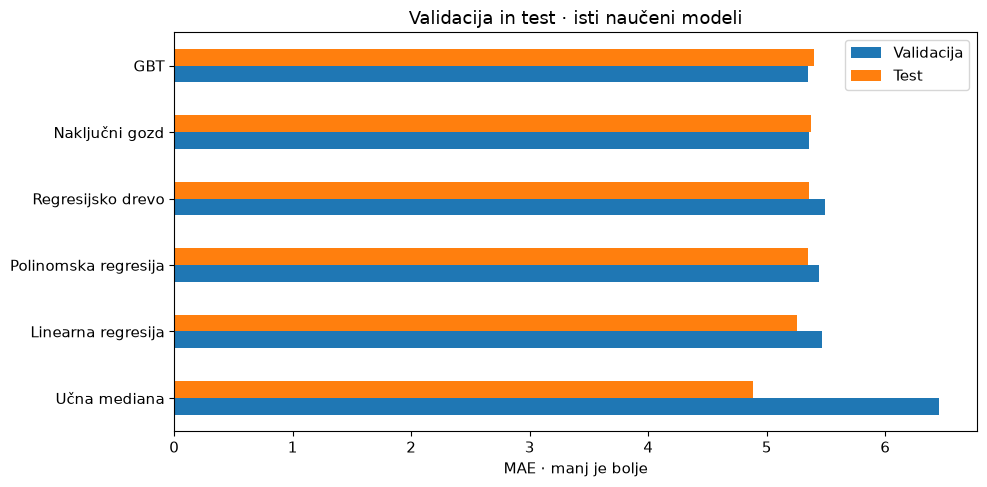

,val_MAE,val_RMSE,val_R2,val_negativnih_napovedi,test_MAE,test_RMSE,test_R2,test_negativnih_napovedi
model,,,,,,,,
Učna mediana,6.4510,9.2205,-0.0171,0,4.8868,6.3084,-0.1744,0
Linearna regresija,5.4648,7.7277,0.2856,0,5.2584,6.4933,-0.2443,0
Polinomska regresija,5.4435,7.7186,0.2873,2,5.3514,6.6540,-0.3067,3
Regresijsko drevo,5.4877,7.7869,0.2746,0,5.3600,6.6608,-0.3093,0
Naključni gozd,5.3591,7.6371,0.3022,0,5.3695,6.6309,-0.2976,0
GBT,5.3449,7.6180,0.3057,0,5.4008,6.6629,-0.3101,0


In [10]:
# Isti modeli na obeh množicah; ni ponovnega učenja na train + val.
pregled=REZULTATI.set_index('model')
fig,ax=plt.subplots(figsize=(10,5))
pregled[[f'val_{GLAVNA_METRIKA}',f'test_{GLAVNA_METRIKA}']].rename(
    columns={f'val_{GLAVNA_METRIKA}':'Validacija',f'test_{GLAVNA_METRIKA}':'Test'}).plot.barh(ax=ax)
ax.set(xlabel=GLAVNA_METRIKA+' · manj je bolje',ylabel='',title='Validacija in test · isti naučeni modeli')
plt.tight_layout();plt.show()
# Vse metrike, ne samo lestvica po glavni metriki.
metricni=[s for s in REZULTATI if s.startswith('val_') or s.startswith('test_')]
display(REZULTATI[['model']+metricni].set_index('model').round(4))

## 6. Izvoz za primerjavo udeležencev
CSV vsebuje oznako udeleženca, modele, obe oceni, seme, dejanske parametre in oznako kandidata, izbranega na validaciji.
JSON shrani še celotno konfiguracijo, različice knjižnic in odtise vhodnih datotek.
Izvoz ne vsebuje posameznih naročnikov, naročil ali njihovih napovedi. Vsak zagon dobi novo ime datoteke.

In [11]:
MAPA_REZULTATOV=KOREN/'data/rezultati_delavnice'/ZBIRKA
IZVOZI=MAPA_REZULTATOV/'izvozi'
ODDAJE=MAPA_REZULTATOV/'oddaje'
IZVOZI.mkdir(parents=True,exist_ok=True)
ODDAJE.mkdir(parents=True,exist_ok=True)
varna_oznaka=re.sub(r'[^A-Za-z0-9_-]+','_',UDELEZENEC.strip()).strip('_') or 'udelezenec'
osnova=f'{varna_oznaka}_{RUN_ID}'
csv_pot=IZVOZI/f'{osnova}.csv'
json_pot=IZVOZI/f'{osnova}.json'
REZULTATI.to_csv(csv_pot,index=False,encoding='utf-8-sig')
paket=dict(protokol=PROTOKOL,protokol_id=PROTOKOL_ID,konfiguracija=ZAMRZNJENO,
           dejanske_nastavitve=DEJANSKE_NASTAVITVE,izbrani_na_validaciji=IZBRANI_NA_VALIDACIJI,
           razlicice=RAZLICICE,run_id=RUN_ID,cas_utc=CAS_UTC)
json_pot.write_text(json.dumps(paket,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
print('Rezultati za primerjavo:',csv_pot.relative_to(KOREN))
print('Nastavitve in protokol:',json_pot.relative_to(KOREN))
print('Mapa za dogovorjene skupne oddaje:',ODDAJE.relative_to(KOREN))

Rezultati za primerjavo: data/rezultati_delavnice/olist/izvozi/primer_predavatelja_20261116T145048_79de09f8.csv
Nastavitve in protokol: data/rezultati_delavnice/olist/izvozi/primer_predavatelja_20261116T145048_79de09f8.json
Mapa za dogovorjene skupne oddaje: data/rezultati_delavnice/olist/oddaje


## 7. Skupna primerjava oddaj
Predavatelj zbere **po en dogovorjeni CSV vsakega udeleženca** v mapo `oddaje`, izpisano zgoraj.
Datoteke prenesete sami; notebook jih nikamor ne pošilja. Nato ponovno izvedite samo naslednjo celico.
Če mapa še nima oddaj, se pokaže lastni pravkar izračunani rezultat.

Prva tabela primerja udeležence po posamezni družini modelov. Druga primerja njihove **na validaciji izbrane kandidate**.
Ne izbiramo naknadno najboljšega testnega modela za vsakega udeleženca. Manjša številka izgube pomeni boljše mesto;
izenačeni rezultati dobijo isto mesto.

Odtisi preprečijo tiho združevanje drugačnih podatkov ali semen. Če je za istega udeleženca več različnih oddaj,
izberite eno vnaprej dogovorjeno oddajo; avtomatsko ne izbiramo najboljše testne ocene.

In [12]:
def zdruzi_oddaje(datoteke,protokol_id):
    vse=[]
    obvezni={'udelezenec','model','run_id','protokol_id','seme','n_jobs','glavna_metrika',
             'izbran_na_validaciji',f'val_{GLAVNA_METRIKA}',f'test_{GLAVNA_METRIKA}'}
    for pot in datoteke:
        df=pd.read_csv(pot,keep_default_na=False,dtype={
            'udelezenec':'string','model':'string','run_id':'string','protokol_id':'string'})
        if not obvezni<=set(df):
            raise ValueError(f'{Path(pot).name}: manjkajo zahtevani stolpci.')
        if not df['protokol_id'].eq(protokol_id).all():
            raise ValueError(f'{Path(pot).name}: drugačni podatki ali protokol; primerjajte ločeno.')
        if not df['seme'].eq(42).all() or not df['n_jobs'].eq(2).all():
            raise ValueError('Za skupno lestvico morajo biti seme in niti enaki.')
        if not df['glavna_metrika'].eq(GLAVNA_METRIKA).all():
            raise ValueError('Glavna metrika mora biti enaka.')
        izbrano=df['izbran_na_validaciji'].astype(str).str.lower()
        if not izbrano.isin(['true','false']).all():
            raise ValueError('Neveljavna oznaka izbranega modela.')
        df['izbran_na_validaciji']=izbrano.eq('true')
        for m in [f'val_{GLAVNA_METRIKA}',f'test_{GLAVNA_METRIKA}']:
            df[m]=pd.to_numeric(df[m],errors='raise')
            if not np.isfinite(df[m]).all():raise ValueError('Metrike morajo biti končne številke.')
        if df.udelezenec.astype(str).str.strip().eq('').any():raise ValueError('Manjka oznaka udeleženca.')
        vse.append(df)
    if not vse:raise ValueError('Ni datotek za primerjavo.')
    tabela=pd.concat(vse,ignore_index=True).drop_duplicates()
    if tabela.duplicated(['udelezenec','run_id','model']).any():
        raise ValueError('Ista oddaja vsebuje nasprotujoče si vrstice.')
    if (tabela.groupby('udelezenec').run_id.nunique()>1).any():
        raise ValueError('Za vsakega udeleženca dajte v mapo eno dogovorjeno oddajo, ne več poskusov.')
    for (udelezenec,run_id),skupina in tabela.groupby(['udelezenec','run_id']):
        if set(skupina.model)!=set(MODELI):raise ValueError(f'{udelezenec}: oddaja mora vsebovati vse modele.')
        if skupina.izbran_na_validaciji.sum()!=1:raise ValueError('Izbran mora biti natanko en model.')
        izbrana=skupina.loc[skupina.izbran_na_validaciji,f'val_{GLAVNA_METRIKA}'].item()
        if not np.isclose(izbrana,skupina[f'val_{GLAVNA_METRIKA}'].min()):
            raise ValueError('Oznaka izbranega modela se ne ujema z validacijskim izborom.')
    return tabela

# Če skupnih oddaj še ni, pokažemo pravkar ustvarjeno lastno oddajo.
datoteke=sorted(ODDAJE.glob('*.csv')) or [csv_pot]
SKUPAJ=zdruzi_oddaje(datoteke,PROTOKOL_ID)
SKUPAJ['mesto_znotraj_modela']=SKUPAJ.groupby('model')[f'test_{GLAVNA_METRIKA}'].rank(method='min',ascending=True).astype(int)
prikaz=['udelezenec','model',f'val_{GLAVNA_METRIKA}',f'test_{GLAVNA_METRIKA}','mesto_znotraj_modela']
display(SKUPAJ[prikaz].sort_values(['model','mesto_znotraj_modela']).round(4))
# Glavna skupna primerjava uporablja model, izbran na validaciji, ne naknadnega zmagovalca testa.
lestvica=SKUPAJ.loc[SKUPAJ.izbran_na_validaciji].copy()
lestvica['mesto']=lestvica[f'test_{GLAVNA_METRIKA}'].rank(method='min',ascending=True).astype(int)
print('Skupna primerjava vnaprej izbranih modelov:')
display(lestvica[['mesto']+prikaz[:-1]].sort_values('mesto').round(4))

,udelezenec,model,val_MAE,test_MAE,mesto_znotraj_modela
5,primer_predavatelja,GBT,5.3449,5.4008,1
1,primer_predavatelja,Linearna regresija,5.4648,5.2584,1
4,primer_predavatelja,Naključni gozd,5.3591,5.3695,1
2,primer_predavatelja,Polinomska regresija,5.4435,5.3514,1
3,primer_predavatelja,Regresijsko drevo,5.4877,5.3600,1
0,primer_predavatelja,Učna mediana,6.4510,4.8868,1


Skupna primerjava vnaprej izbranih modelov:


,mesto,udelezenec,model,val_MAE,test_MAE
5,1,primer_predavatelja,GBT,5.3449,5.4008


## Razprava
- Ali je vrstni red modelov na testu enak kot na validaciji?
- Kateri model ima največjo razliko med ocenama in kako bi jo lahko razložili?
- Ali so razlike med udeleženci dovolj velike za praktično odločitev?
- Kaj je poleg glavne metrike pomembno: vrste napak, čas računanja, zahtevnost in razložljivost?

Lestvica je vaja, ne dokaz statistično zanesljive prednosti. Rezultat posamezne oddaje je povezan tudi z izbranim naborom značilk.
Shranite CSV in JSON; podrobnosti nastavitev so del rezultata.